# Part 1 — Data Science & ML: Predict Dropout

Goal: predict which students will drop out, so we can help them early.

Steps (see task brief):
1. Explore — 3–4 findings, a chart for each.
2. Clean — explain **every** cleaning decision (log it).
3. Features — build what matters, explain why. **Do not use `refund_requested`.**
4. Model — train one model + compare to a simple baseline.
5. Evaluate — precision / recall / F1; say which matters more here and why.
6. Importance — which features matter most; what I chose not to use and why.

Rules: simple readable code, fixed seed, log cleaning decisions (see `CLAUDE.md`).

In [1]:
# Setup
import sys
sys.path.insert(0, "..")  # so `from src...` works when running from notebooks/

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

from src.data import load_raw, load_clean, cleaning_log
from src.features import build_features, last_attempt_day, WINDOW_DAYS
from src.model import make_logreg, cv_summary

SEED = 42  # fixed seed for reproducibility
CHART_DIR = "../outputs/charts/"
JSON_DIR = "../outputs/json/"

# Two series everywhere: completed vs dropped out (categorical slots 1 and 2).
COLORS = {"no": "#2a78d6", "yes": "#eb6834"}
LABELS = {"no": "Completed", "yes": "Dropped out"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "axes.axisbelow": True})

## 1. Explore

First, check the raw data before trusting it (the dataset README warns about this).

In [2]:
raw = load_raw()
for name, df in raw.items():
    missing = df.isna().sum()
    print(f"{name}: {len(df)} rows | missing: {missing[missing > 0].to_dict()}")

q = raw["quiz"]
print("\nquiz scores outside 0-100:", ((q.score < 0) | (q.score > 100)).sum(), "->", sorted(q.score[q.score > 100].unique()))
print("quiz rows identical except attempt_id:", q.drop(columns="attempt_id").duplicated().sum())
print("students with no quiz attempt:", (~raw["students"].student_id.isin(q.student_id)).sum())
print("dropout rate:", f"{(raw['outcome'].dropped_out == 'yes').mean():.0%}")

students: 500 rows | missing: {'age_group': 21, 'device': 16}
quiz: 2453 rows | missing: {'time_spent_min': 95}
explanations: 724 rows | missing: {'label': 664}
outcome: 500 rows | missing: {}

quiz scores outside 0-100: 3 -> [np.int64(999)]
quiz rows identical except attempt_id: 18
students with no quiz attempt: 1
dropout rate: 25%


Those issues are fixed in section 2. For the charts below I join the raw tables and only
exclude the three `999` scores (the 18 duplicate rows are too few to change any picture).

In [3]:
students = raw["students"].merge(raw["outcome"], on="student_id")
quiz = raw["quiz"][raw["quiz"].score <= 100].merge(students[["student_id", "signup_date", "dropped_out"]], on="student_id")
quiz["days_since_signup"] = (pd.to_datetime(quiz.attempted_at) - pd.to_datetime(quiz.signup_date)).dt.days
group_sizes = students.dropped_out.value_counts()

### Finding 1 — `refund_requested` is almost the outcome itself

dropped_out        no  yes  All
refund_requested               
no                364   19  383
yes                11  106  117
All               375  125  500


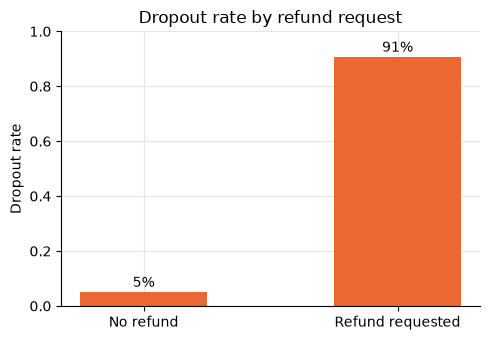

In [4]:
rate = students.groupby("refund_requested").dropped_out.apply(lambda s: (s == "yes").mean())
print(pd.crosstab(students.refund_requested, students.dropped_out, margins=True))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["No refund", "Refund requested"], rate.values, color=COLORS["yes"], width=0.5)
for i, v in enumerate(rate.values):
    ax.text(i, v + 0.02, f"{v:.0%}", ha="center")
ax.set_ylim(0, 1)
ax.set_ylabel("Dropout rate")
ax.set_title("Dropout rate by refund request")
fig.tight_layout()
fig.savefig(CHART_DIR + "p1_refund_vs_dropout.png", dpi=150)
plt.show()

### Finding 2 — dropouts fall off the lesson path

lesson_id      L1    L2    L3
dropped_out                  
no           1.00  0.93  0.75
yes          0.98  0.63  0.44


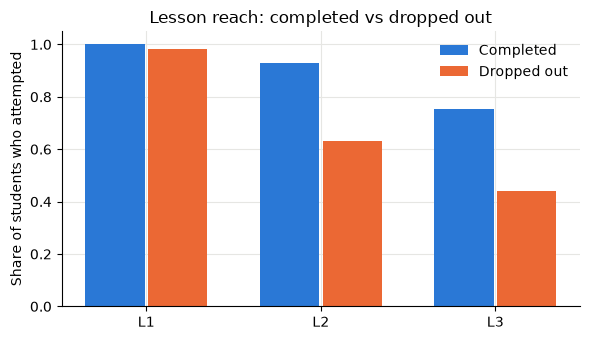

In [5]:
reached = quiz.groupby(["dropped_out", "lesson_id"]).student_id.nunique().unstack()
reached = reached.div(group_sizes, axis=0)  # share of each group that attempted the lesson
print(reached.round(2))

fig, ax = plt.subplots(figsize=(6, 3.5))
lessons = reached.columns
for i, group in enumerate(["no", "yes"]):
    x = [j + (i - 0.5) * 0.36 for j in range(len(lessons))]
    ax.bar(x, reached.loc[group], width=0.34, color=COLORS[group], label=LABELS[group])
ax.set_xticks(range(len(lessons)), lessons)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Share of students who attempted")
ax.set_title("Lesson reach: completed vs dropped out")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(CHART_DIR + "p1_lesson_reach.png", dpi=150)
plt.show()

### Finding 3 — dropouts score lower, but the groups overlap a lot

             count  mean   std   min   25%   50%   75%    max
dropped_out                                                  
no           375.0  71.6  10.5  41.5  65.1  71.7  79.5  100.0
yes          124.0  61.9  11.7  36.7  53.7  62.7  69.7   85.0


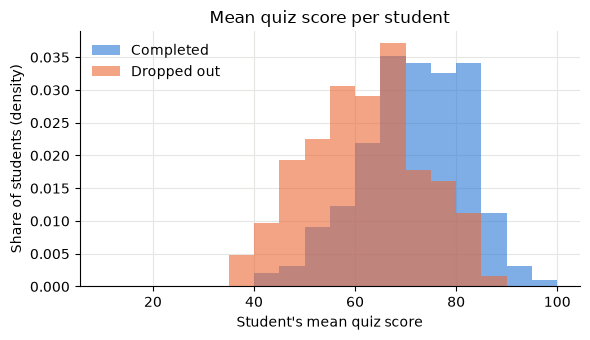

In [6]:
mean_score = quiz.groupby(["student_id", "dropped_out"]).score.mean().reset_index()
print(mean_score.groupby("dropped_out").score.describe().round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))
for group in ["no", "yes"]:
    ax.hist(mean_score[mean_score.dropped_out == group].score, bins=range(10, 101, 5),
            alpha=0.6, color=COLORS[group], label=LABELS[group], density=True)
ax.set_xlabel("Student's mean quiz score")
ax.set_ylabel("Share of students (density)")
ax.set_title("Mean quiz score per student")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(CHART_DIR + "p1_mean_score.png", dpi=150)
plt.show()

### Finding 4 — dropouts stop early, so *when* we look matters

             count  mean   std  min   25%   50%   75%    max
dropped_out                                                 
no           375.0  46.9  19.8  6.0  32.0  44.0  59.0  104.0
yes          124.0  19.4  14.1  0.0   9.0  15.0  29.0   54.0


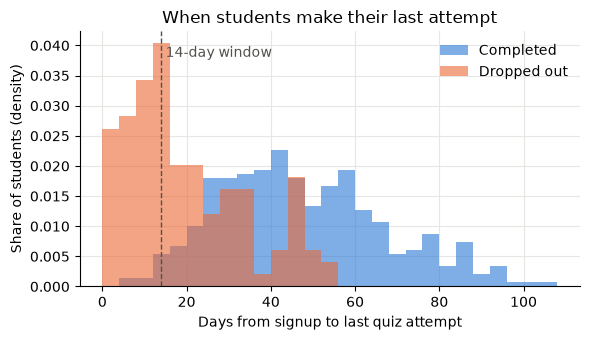

In [7]:
last_day = quiz.groupby(["student_id", "dropped_out"]).days_since_signup.max().reset_index()
print(last_day.groupby("dropped_out").days_since_signup.describe().round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))
for group in ["no", "yes"]:
    ax.hist(last_day[last_day.dropped_out == group].days_since_signup, bins=range(0, 110, 4),
            alpha=0.6, color=COLORS[group], label=LABELS[group], density=True)
ax.axvline(WINDOW_DAYS, color="#52514e", linestyle="--", linewidth=1)
ax.text(WINDOW_DAYS + 1, ax.get_ylim()[1] * 0.9, f"{WINDOW_DAYS}-day window", color="#52514e")
ax.set_xlabel("Days from signup to last quiz attempt")
ax.set_ylabel("Share of students (density)")
ax.set_title("When students make their last attempt")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(CHART_DIR + "p1_last_attempt_day.png", dpi=150)
plt.show()

**Findings summary**

1. **`refund_requested` leaks the outcome.** 106 of 117 refund requesters dropped out (91%) vs 19 of 383
   others (5%). A refund is part of leaving, not an early sign of it → excluded from the model.
2. **Dropouts leave between Lesson 1 and Lesson 2.** Nearly everyone attempts L1 (98% vs 100%), but only
   63% of dropouts reach L2 (vs 93%) and 44% reach L3 (vs 75%). → *lessons reached* is a feature.
3. **Dropouts score ~10 points lower** (mean 62 vs 72), but the distributions overlap heavily, so score
   helps but won't separate the groups on its own. → mean / min score are features.
4. **Dropouts stop early.** Median last attempt: day 15 after signup for dropouts vs day 44 for completers.
   So an early-warning model must only look at early activity — features built from full history mostly
   measure *that the student already stopped*. This motivates the time window below.

## 2. Clean (log every decision)

All cleaning lives in `src/data.py`. Each step prints one line and is collected in a log table.
The raw files are never edited.

In [8]:
data = load_clean()
cleaning_log()

[clean] students: filled missing age_group with 'unknown' (21 rows) - keep these students; missing is its own category rather than a guess
[clean] students: filled missing device with 'unknown' (16 rows) - keep these students; missing is its own category rather than a guess
[clean] quiz: dropped scores outside 0-100 (all were 999) (3 rows) - impossible value, looks like a placeholder/error code
[clean] quiz: dropped duplicate attempts (identical except attempt_id) (18 rows) - double-logged rows would inflate attempt counts
[clean] quiz: left missing time_spent_min as missing (95 rows) - missing at a similar rate for both groups; imputed per CV fold inside the model Pipeline
[clean] outcome: mapped dropped_out yes/no to 1/0 (500 rows) - numeric target for modelling


,table,what,rows,why
0,students,filled missing age_group with 'unknown',21,keep these students; missing is its own catego...
1,students,filled missing device with 'unknown',16,keep these students; missing is its own catego...
2,quiz,dropped scores outside 0-100 (all were 999),3,"impossible value, looks like a placeholder/err..."
3,quiz,dropped duplicate attempts (identical except a...,18,double-logged rows would inflate attempt counts
4,quiz,left missing time_spent_min as missing,95,missing at a similar rate for both groups; imp...
5,outcome,mapped dropped_out yes/no to 1/0,500,numeric target for modelling


Why each decision:

| Step | Decision | Why |
|---|---|---|
| Missing `age_group` / `device` | fill with `"unknown"` | only 37 students; dropping them loses outcomes, guessing a value invents data |
| Scores of `999` | drop the 3 rows | impossible on a 0–100 scale, looks like an error code |
| Duplicate attempts | drop 18 copies | same student/lesson/score/time/minute but a new `attempt_id` = logged twice; would inflate attempt counts |
| Missing `time_spent_min` | leave missing here | ~4% of rows, missing at a similar rate for both groups, so not a signal. Filling with a median over *all* students would leak across CV folds, so imputation happens inside the model Pipeline (median, fitted per training fold) |
| `dropped_out` | yes/no → 1/0 | numeric target |

What I deliberately did **not** do: drop the one student with no quiz attempts (zero activity is real
information), or touch `refund_requested` (kept for exploration, excluded from features).

**Rule of thumb used:** cleaning only applies fixed, row-level rules (drop impossible values, drop
duplicates, label missing categories). Anything *learned from the data* — medians, scaling, one-hot
categories — lives in the sklearn Pipeline in `src/model.py`, so it is re-fitted on each training fold.

In [9]:
# Sanity checks after cleaning
assert data["quiz"].score.between(0, 100).all()
assert not data["quiz"].drop(columns="attempt_id").duplicated().any()
assert data["students"][["age_group", "device"]].notna().all().all()
print({name: len(df) for name, df in data.items()})

{'students': 500, 'quiz': 2432, 'outcome': 500}


### Window comparison — how much early activity should the model see?

Features come from each student's first `N` days after signup (`src/features.py`). Same model at
every window: the logistic regression Pipeline from `src/model.py` (median-impute + scale numbers,
one-hot categories, `class_weight="balanced"` because only 25% drop out), 5-fold stratified CV, seed 42.
AUC is shown as mean ± std across the 5 folds.

`dropouts_already_stopped` = share of dropouts whose last quiz attempt is before the window ends.
At that point the window isn't *predicting* their dropout any more — it's watching it happen.

In [10]:
WINDOWS = [7, 14, 21, 28, None]  # None = full history
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

y = data["outcome"].set_index("student_id").dropped_out
last_day = last_attempt_day(data["students"], data["quiz"])
dropout_last_day = last_day[y[last_day.index] == 1]

rows = []
for window in WINDOWS:
    X = build_features(data["students"], data["quiz"], window_days=window)
    s = cv_summary(make_logreg(SEED), X, y[X.index], cv)
    rows.append({
        "window": "full history" if window is None else f"{window} days",
        "auc_mean": s["auc"][0],
        "auc_std": s["auc"][1],
        "precision": s["precision"][0],
        "recall": s["recall"][0],
        "f1": s["f1"][0],
        "dropouts_already_stopped": 1.0 if window is None else (dropout_last_day < window).mean(),
    })

window_results = pd.DataFrame(rows).round(3)
window_results.to_json(JSON_DIR + "p1_window_comparison.json", orient="records", indent=2)
window_results

,window,auc_mean,auc_std,precision,recall,f1,dropouts_already_stopped
0,7 days,0.723,0.064,0.456,0.616,0.523,0.200
1,14 days,0.772,0.040,0.455,0.680,0.544,0.416
2,21 days,0.792,0.026,0.473,0.752,0.578,0.600
3,28 days,0.812,0.026,0.488,0.744,0.587,0.728
4,full history,0.900,0.020,0.591,0.808,0.680,1.000


**Reading the table**

- **Full history is a leak, not a better model.** It has the best scores (AUC 0.90 ± 0.02, F1 0.68), but
  by definition 100% of dropouts have already made their last attempt, so the model is detecting the
  stop, not predicting it. Not usable for early warning.
- **Neighbouring windows are within noise on AUC.** 7 → 14 days is +0.05 but the fold std is 0.04–0.06;
  14 → 21 and 21 → 28 are +0.02 against a std of ~0.03. With 125 dropouts (~25 per test fold) one fold
  can swing AUC a lot. So the table does **not** show that 14 days is the most accurate window — only
  that accuracy rises gently with window length, and that the 7-day model is the least stable (std 0.064).
- **What *is* clear-cut is timing.** The share of dropouts already gone rises fast:
  20% → 42% → 60% → 73%. That is a fact about the data, not a noisy estimate.
- **Why 14 days, then:**
  - It is the longest window where most dropouts (58%) are still active, so there is still someone to
    help. At 21 days most (60%) have already stopped.
  - One week is thin data: 195 of 500 students have no attempt yet at day 7, vs 59 at day 14, and
    the 7-day model's AUC varies most across folds.
  - The extra accuracy from 21–28 days is small and within noise, and is bought by waiting for students
    to leave.
- **Caveat:** 42% of dropouts have already stopped by day 14 — the model is early for the majority, not
  for everyone. A 7-day model is the option if catching the earliest leavers matters more than stability.

→ `WINDOW_DAYS = 14` in `src/features.py`.

## 3. Features
_TODO_

## 4. Model + baseline
_TODO_

## 5. Evaluate (precision / recall / F1)
_TODO_

## 6. Feature importance + what I didn't use
_TODO_